In [1]:
modules = ["pandas", "numpy", "matplotlib", "missingno", "seaborn"]

import sys
import os.path
from subprocess import check_call
import importlib
import os

def instala(modules):
  print("Instalando módulos")
  for m in modules:
      # para el import quitamos [...] y ==...
      p = m.find("[")
      mi = m if p==-1 else m[:p]
      p = mi.find("==")
      mi = mi if p==-1 else mi[:p]

      torch_loader = importlib.util.find_spec(mi)
      if torch_loader is not None:
          print(m," encontrado")
      else:
          print(m," No encontrado, instalando...",end="")  
          try:        
            r = check_call([sys.executable, "-m", "pip", "install", "--user", m])
            print("¡hecho! (Reiniciar kernel)")
          except:
            print("¡Problema al instalar ",m,"! ¿seguro que el módulo existe?",sep="")
              
  print("¡Terminado!")

instala(modules)

Instalando módulos
pandas  encontrado
numpy  encontrado
matplotlib  encontrado
missingno  encontrado
seaborn  encontrado
¡Terminado!


In [6]:
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [4]:
path = r'../../data/datos_hashrate_limpiados_binance.csv'
df_merged = pd.read_csv(path, header=0)

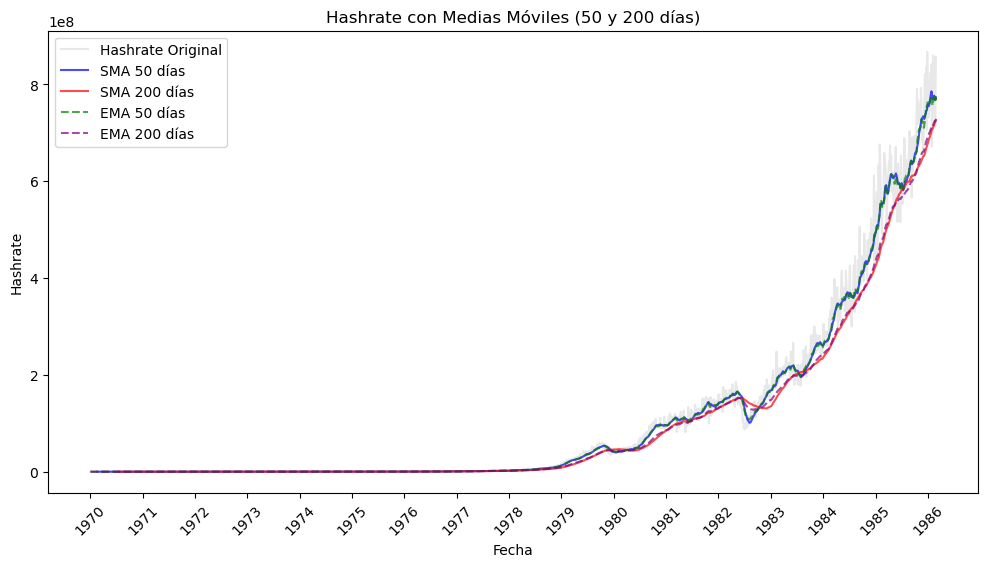

In [7]:
# Graficar las medias móviles
plt.figure(figsize=(12, 6))
plt.plot(df_merged['timestamp'], df_merged['hashrate'], label='Hashrate Original', color='lightgray', alpha=0.5)
plt.plot(df_merged['timestamp'], df_merged['SMA_50'], label='SMA 50 días', color='blue', alpha=0.7)
plt.plot(df_merged['timestamp'], df_merged['SMA_200'], label='SMA 200 días', color='red', alpha=0.7)
plt.plot(df_merged['timestamp'], df_merged['EMA_50'], label='EMA 50 días', color='green', linestyle='dashed',
         alpha=0.7)
plt.plot(df_merged['timestamp'], df_merged['EMA_200'], label='EMA 200 días', color='purple', linestyle='dashed',
         alpha=0.7)
plt.xlabel('Fecha')
plt.ylabel('Hashrate')
plt.title('Hashrate con Medias Móviles (50 y 200 días)')
plt.legend()
plt.gca().xaxis.set_major_locator(mdates.YearLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
plt.show()